In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


In [2]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Ruta a la carpeta train
base_traing = r"C:\Users\rafit\OneDrive\Escritorio\archive\casting_data\casting_data\train"

# Asignación explícita para que OK sea 0 y Defectuosa sea 1
ok_traing = os.path.join(base_traing, "ok_front")
def_traing = os.path.join(base_traing, "def_front")

print(f"Leyendo clase 0 (OK) desde: ok_front")
print(f"Leyendo clase 1 (Defectuosa) desde: def_front")

extensiones = ('.jpg', '.jpeg', '.png', '.bmp')
files_ok = sorted([f for f in os.listdir(ok_traing) if f.lower().endswith(extensiones)])
files_def = sorted([f for f in os.listdir(def_traing) if f.lower().endswith(extensiones)])

def cargar_imagenes_validas(path, files):
    imgs = []
    for f in files:
        img = cv2.imread(os.path.join(path, f))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            imgs.append(img)
    return imgs

imgs_ok = cargar_imagenes_validas(ok_traing, files_ok)
imgs_def = cargar_imagenes_validas(def_traing, files_def)

def normalizar_imagenes(imgs, size=(128, 128)):
    imgs_norm = []
    for img in imgs:
        if img is not None:
            img_resized = cv2.resize(img, size)
            img_norm = img_resized.astype("float32") / 255.0
            imgs_norm.append(img_norm)
    return np.array(imgs_norm)

norm_ok = normalizar_imagenes(imgs_ok)
norm_def = normalizar_imagenes(imgs_def)

# 0 para OK, 1 para Defectuosa
X = np.concatenate((norm_ok, norm_def), axis=0)
y = np.concatenate((np.zeros(len(norm_ok)), np.ones(len(norm_def))), axis=0)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Dataset listo -> Train: {X_train.shape}, Validación: {X_val.shape}")

# Funciones de extracción
def extraer_hog(imagenes):
    hog_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        features = hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)
        lbp_features.append(hist)
    return np.array(lbp_features)

def extraer_glcm(imagenes, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    glcm_features = []
    propiedades = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        img_gray_q = (img_gray // 4).astype(np.uint8)
        glcm = graycomatrix(img_gray_q, distances=distances, angles=angles, levels=64, symmetric=True, normed=True)
        vector_img = []
        for prop in propiedades:
            valores = graycoprops(glcm, prop).ravel()
            vector_img.extend(valores)
        glcm_features.append(vector_img)
    return np.array(glcm_features)

print("\nExtrayendo HOG...")
X_train_hog = extraer_hog(X_train)
X_val_hog = extraer_hog(X_val)

print("Extrayendo LBP...")
X_train_lbp = extraer_lbp(X_train)
X_val_lbp = extraer_lbp(X_val)

print("Extrayendo GLCM...")
X_train_glcm = extraer_glcm(X_train)
X_val_glcm = extraer_glcm(X_val)

X_train_fusion = np.hstack((X_train_hog, X_train_lbp, X_train_glcm))
X_val_fusion = np.hstack((X_val_hog, X_val_lbp, X_val_glcm))

scaler_fusion = StandardScaler()
X_train_fusion_scaled = scaler_fusion.fit_transform(X_train_fusion)
X_val_fusion_scaled = scaler_fusion.transform(X_val_fusion)

output_dir = r"C:\Users\rafit\OneDrive\Escritorio\archive\casting_data\features"
os.makedirs(output_dir, exist_ok=True)

scaler_hog = StandardScaler()
X_tr_hog_sc = scaler_hog.fit_transform(X_train_hog)
X_va_hog_sc = scaler_hog.transform(X_val_hog)

scaler_lbp = StandardScaler()
X_tr_lbp_sc = scaler_lbp.fit_transform(X_train_lbp)
X_va_lbp_sc = scaler_lbp.transform(X_val_lbp)

scaler_glcm = StandardScaler()
X_tr_glcm_sc = scaler_glcm.fit_transform(X_train_glcm)
X_va_glcm_sc = scaler_glcm.transform(X_val_glcm)

np.savez_compressed(os.path.join(output_dir, "features_hog.npz"), X_train=X_tr_hog_sc, X_val=X_va_hog_sc, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_lbp.npz"), X_train=X_tr_lbp_sc, X_val=X_va_lbp_sc, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_glcm.npz"), X_train=X_tr_glcm_sc, X_val=X_va_glcm_sc, y_train=y_train, y_val=y_val)
np.savez_compressed(os.path.join(output_dir, "features_fusion.npz"), X_train=X_train_fusion_scaled, X_val=X_val_fusion_scaled, y_train=y_train, y_val=y_val)

print("\n¡Listo! Características extraídas y guardadas con éxito en formato .npz.")

Leyendo clase 0 (OK) desde: ok_front
Leyendo clase 1 (Defectuosa) desde: def_front
Dataset listo -> Train: (4643, 128, 128, 3), Validación: (1990, 128, 128, 3)

Extrayendo HOG...
Extrayendo LBP...
Extrayendo GLCM...

¡Listo! Características extraídas y guardadas con éxito en formato .npz.


In [3]:
import os
import cv2
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

base_traing = r"C:\Users\rafit\OneDrive\Escritorio\archive\casting_data\casting_data\train"

ok_traing = os.path.join(base_traing, "ok_front")
def_traing = os.path.join(base_traing, "def_front")

extensiones = ('.jpg', '.jpeg', '.png', '.bmp')
files_ok = sorted([f for f in os.listdir(ok_traing) if f.lower().endswith(extensiones)])
files_def = sorted([f for f in os.listdir(def_traing) if f.lower().endswith(extensiones)])

# Limitamos a 600 imágenes por clase (1,200 en total) para que vuele el código y no se congele
MAX_IMGS_POR_CLASE = 600 
files_ok = files_ok[:MAX_IMGS_POR_CLASE]
files_def = files_def[:MAX_IMGS_POR_CLASE]

def cargar_imagenes_validas(path, files):
    imgs = []
    for f in files:
        img = cv2.imread(os.path.join(path, f))
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            imgs.append(img)
    return imgs

print("Cargando imágenes optimizadas...")
imgs_ok = cargar_imagenes_validas(ok_traing, files_ok)
imgs_def = cargar_imagenes_validas(def_traing, files_def)

def normalizar_imagenes(imgs, size=(64, 64)): # Reducimos a 64x64 para aligerar el HOG y GLCM
    imgs_norm = []
    for img in imgs:
        if img is not None:
            img_resized = cv2.resize(img, size)
            img_norm = img_resized.astype("float32") / 255.0
            imgs_norm.append(img_norm)
    return np.array(imgs_norm)

norm_ok = normalizar_imagenes(imgs_ok)
norm_def = normalizar_imagenes(imgs_def)

X = np.concatenate((norm_ok, norm_def), axis=0)
y = np.concatenate((np.zeros(len(norm_ok)), np.ones(len(norm_def))), axis=0)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(f"Dataset reducido listo -> Train: {X_train.shape}, Validación: {X_val.shape}")

def extraer_hog(imagenes):
    hog_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        features = hog(img_gray, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(img_gray, P=P, R=R, method="uniform")
        (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)
        lbp_features.append(hist)
    return np.array(lbp_features)

def extraer_glcm(imagenes, distances=[1], angles=[0]): # Simplificado para velocidad
    glcm_features = []
    propiedades = ['contrast', 'homogeneity', 'energy']
    for img in imagenes:
        img_gray = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        img_gray_q = (img_gray // 4).astype(np.uint8)
        glcm = graycomatrix(img_gray_q, distances=distances, angles=angles, levels=64, symmetric=True, normed=True)
        vector_img = []
        for prop in propiedades:
            valores = graycoprops(glcm, prop).ravel()
            vector_img.extend(valores)
        glcm_features.append(vector_img)
    return np.array(glcm_features)

print("Extrayendo características rápidamente...")
X_train_hog, X_val_hog = extraer_hog(X_train), extraer_hog(X_val)
X_train_lbp, X_val_lbp = extraer_lbp(X_train), extraer_lbp(X_val)
X_train_glcm, X_val_glcm = extraer_glcm(X_train), extraer_glcm(X_val)

X_train_fusion = np.hstack((X_train_hog, X_train_lbp, X_train_glcm))
X_val_fusion = np.hstack((X_val_hog, X_val_lbp, X_val_glcm))

output_dir = r"C:\Users\rafit\OneDrive\Escritorio\archive\casting_data\features"
os.makedirs(output_dir, exist_ok=True)

def guardar_escalado(tr, va, nombre):
    sc = StandardScaler()
    tr_sc = sc.fit_transform(tr)
    va_sc = sc.transform(va)
    np.savez_compressed(os.path.join(output_dir, nombre), X_train=tr_sc, X_val=va_sc, y_train=y_train, y_val=y_val)

guardar_escalado(X_train_hog, X_val_hog, "features_hog.npz")
guardar_escalado(X_train_lbp, X_val_lbp, "features_lbp.npz")
guardar_exc = guardar_escalado(X_train_glcm, X_val_glcm, "features_glcm.npz")
guardar_escalado(X_train_fusion, X_val_fusion, "features_fusion.npz")

print("\n¡Proceso ultra rápido completado con éxito!")

Cargando imágenes optimizadas...
Dataset reducido listo -> Train: (840, 64, 64, 3), Validación: (360, 64, 64, 3)
Extrayendo características rápidamente...

¡Proceso ultra rápido completado con éxito!


Iniciando Benchmark de Modelos y Descriptores...

TABLA CONSOLIDADA DE BENCHMARK (CONTROL DE CALIDAD - PIEZAS FUNDIDAS)
           Descriptor        Modelo  Dimensiones  Accuracy  Precision   Recall  F1-Score  Tiempo (s)
                  HOG    k-NN (k=5)         1764  0.786111   0.990476 0.577778  0.729825    3.583463
                  HOG     SVM (RBF)         1764  0.930556   0.964072 0.894444  0.927954    3.119838
                  HOG Random Forest         1764  0.808333   0.803279 0.816667  0.809917    0.436629
                  LBP    k-NN (k=5)           10  0.677778   0.710526 0.600000  0.650602    0.046145
                  LBP     SVM (RBF)           10  0.733333   0.759259 0.683333  0.719298    0.068238
                  LBP Random Forest           10  0.725000   0.742515 0.688889  0.714697    0.199041
                 GLCM    k-NN (k=5)            3  0.713889   0.739130 0.661111  0.697947    0.048506
                 GLCM     SVM (RBF)            3  0.697222   0.779528 0.

<Figure size 1200x600 with 0 Axes>

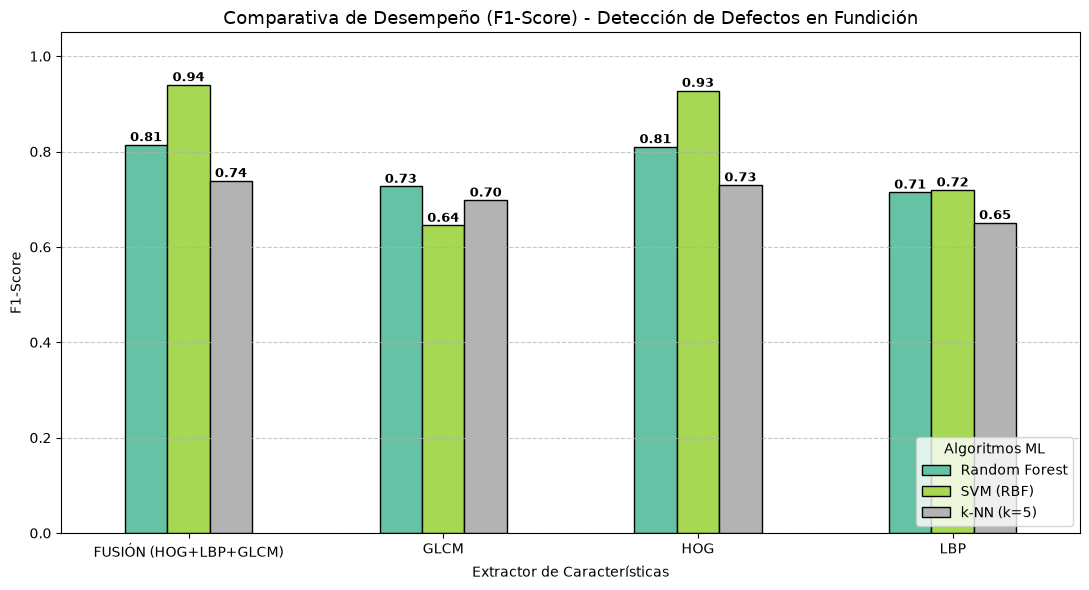

In [4]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

features_dir = r"C:\Users\rafit\OneDrive\Escritorio\archive\casting_data\features"

feature_files = {
    'HOG': 'features_hog.npz',
    'LBP': 'features_lbp.npz',
    'GLCM': 'features_glcm.npz',
    'FUSIÓN (HOG+LBP+GLCM)': 'features_fusion.npz'
}

models = {
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5, metric='euclidean', n_jobs=-1),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
}

results = []

print("Iniciando Benchmark de Modelos y Descriptores...\n")

for feat_name, file_name in feature_files.items():
    path = os.path.join(features_dir, file_name)
    data = np.load(path)
    
    X_train, X_val = data['X_train'], data['X_val']
    y_train, y_val = data['y_train'], data['y_val']
    
    for model_name, model in models.items():
        t0 = time.time()
        
        model.fit(X_train, y_train)
        y_pred = model.predict(X_val)
        t_exec = time.time() - t0
        
        acc = accuracy_score(y_val, y_pred)
        prec = precision_score(y_val, y_pred, average='binary', zero_division=0)
        rec = recall_score(y_val, y_pred, average='binary', zero_division=0)
        f1 = f1_score(y_val, y_pred, average='binary', zero_division=0)
        
        results.append({
            'Descriptor': feat_name,
            'Modelo': model_name,
            'Dimensiones': X_train.shape[1],
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1,
            'Tiempo (s)': t_exec
        })

df_results = pd.DataFrame(results)

print("="*85)
print("TABLA CONSOLIDADA DE BENCHMARK (CONTROL DE CALIDAD - PIEZAS FUNDIDAS)")
print("="*85)
print(df_results.to_string(index=False))

plt.figure(figsize=(12, 6))
df_pivot = df_results.pivot(index='Descriptor', columns='Modelo', values='F1-Score')

ax = df_pivot.plot(kind='bar', figsize=(11, 6), colormap='Set2', edgecolor='black')
plt.title("Comparativa de Desempeño (F1-Score) - Detección de Defectos en Fundición", fontsize=13)
plt.ylabel("F1-Score")
plt.xlabel("Extractor de Características")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title="Algoritmos ML", loc='lower right')

for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', xytext=(0, 5), 
                    textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()